# 01 - Matplotlib Basics (Line Graphs in Matplotlib)
*Codecademy: Analyze Financial Data with Python / Visualizing Finance Data*

**Section goal:** chart financial data with Matplotlib, then use it for mean-variance portfolio optimization (choosing assets that balance expected return against risk).

- Every example saves its chart to `charts/`; all charts are also collected in this folder's [README](README.md) (the gallery page).
- Run cell by cell in VS Code (needs `py -m pip install ipykernel` once).
- On Codecademy the first line is `import codecademylib` - delete it locally.

**R comparison:** matplotlib ~ base R `plot()` / ggplot2 - closer to base R: you build a chart step by step with calls.

## 1. Importing Matplotlib
**Task:** import the plotting functions as `plt`.

In [1]:
from matplotlib import pyplot as plt

CHARTS = 'charts/'   # where the PNGs go (folder next to this notebook)

```text
from  matplotlib  import  pyplot  as  plt
      \________/          \____/      \_/
       package            submodule   short nickname
                          (the plotting functions)
```

The same thing, in the form you'll see more often online: `import matplotlib.pyplot as plt`.
`plt` / `np` / `pd` are conventions everyone uses.

## 2. Basic Line Plot
**Task:** plot lunch spending (`money_spent`) over 7 days and show it.

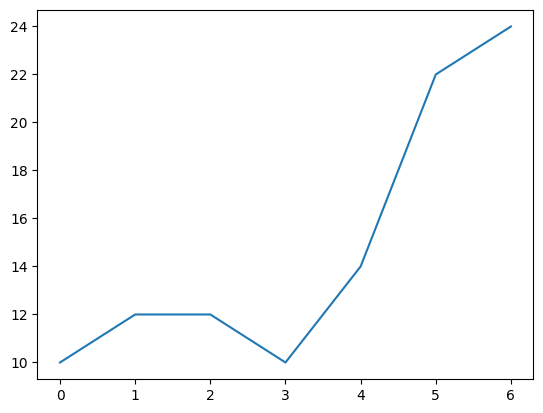

In [2]:
days = [0, 1, 2, 3, 4, 5, 6]
money_spent = [10, 12, 12, 10, 14, 22, 24]

plt.figure()                                   # start a new, empty chart
plt.plot(days, money_spent)                    # build the line (in memory)
plt.savefig(CHARTS + '01_basic_line_plot.png') # save it (optional)
plt.show()                                     # display it

### The pattern - every chart in this notebook follows it

| step | code | what happens |
|---|---|---|
| 1. prepare data | `x = [...]`, `y = [...]` | same length! |
| 2. new figure | `plt.figure()` | blank canvas |
| 3. build the chart | `plt.plot(x, y)` + labels, title... | **nothing visible yet** - it only draws in memory |
| 4. save it | `plt.savefig('...png')` | optional, **before** `show()` |
| 5. display it | `plt.show()` | the chart appears |

- `plt.plot()` alone shows **nothing** - like a value without `print()` in a script.
- `savefig()` **after** `show()` gives a blank image, because `show()` clears the figure.
- `plt.figure()` isn't in the course code (Codecademy shows every exercise separately). Here it guarantees each chart starts empty, so lines from the previous example can't leak in.

```text
plt.plot(x, y)
         ^  ^
         |  +-- y: goes UP the vertical axis
         +----- x: goes ALONG the bottom      (x ALWAYS first)
```

## 3. Basic Line Plot II - multiple lines
**Task:** plot `revenue` vs `time` and `costs` vs `time` on the same axes.

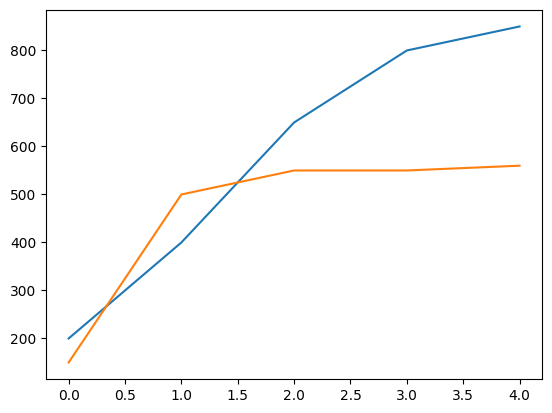

In [3]:
time = [0, 1, 2, 3, 4]
revenue = [200, 400, 650, 800, 850]
costs = [150, 500, 550, 550, 560]

plt.figure()
plt.plot(time, revenue)        # 1st line -> blue by default
plt.plot(time, costs)          # 2nd line -> orange by default
plt.savefig(CHARTS + '02_multiple_lines.png')
plt.show()

**Rule:** everything plotted between two `show()` calls lands on **one** chart.

**Learning point (found by experimenting):** a `show()` in between splits them:
```python
plt.plot(time, revenue)
plt.show()               # shows revenue, then CLEARS the figure
plt.plot(time, costs)
plt.show()               # new empty figure -> only costs
```

**Finance reading:** the gap between the lines is profit. At time 1, costs (500) are above revenue (400), so that's a loss period; after that revenue pulls ahead and the gap widens.

## 4. Linestyles
**Task:** revenue as a purple dashed line; costs in `#82edc9` with square markers.

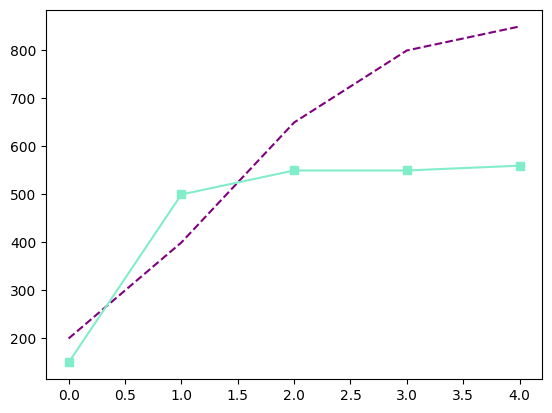

In [4]:
plt.figure()
plt.plot(time, revenue, color='purple', linestyle='--')
plt.plot(time, costs, color='#82edc9', marker='s')
plt.savefig(CHARTS + '03_linestyles.png')
plt.show()

| keyword | short | values |
|---|---|---|
| `color` | `c` | `'green'`, `'#82edc9'` (HEX), `'b' 'g' 'r' 'k'` ... |
| `linestyle` | `ls` | `'-'` solid, `'--'` dashed, `':'` dotted, `'-.'` dash-dot, `''` no line |
| `marker` | | `'o'` circle, `'s'` square, `'*'` star, `'^'` triangle, `'D'` diamond |
| `linewidth` | `lw` | number, e.g. `2` |
| `markersize` | `ms` | number, e.g. `8` |

**Shortcut from the docs - format string** `'[marker][line][color]'`:
```python
plt.plot(x, y, 'o--g')   # circles, dashed, green
plt.plot(x, y, '^k:')    # black triangles, dotted
# = plt.plot(x, y, marker='o', linestyle='--', color='green')
```
Keywords are easier to read; if both are given, the keyword wins. HEX colours don't fit in the shortcut, so they stay as `color='#82edc9'`.

### Mistake made: x and y swapped
I first wrote `plt.plot(revenue, time)`. No error - just a wrong-looking chart:

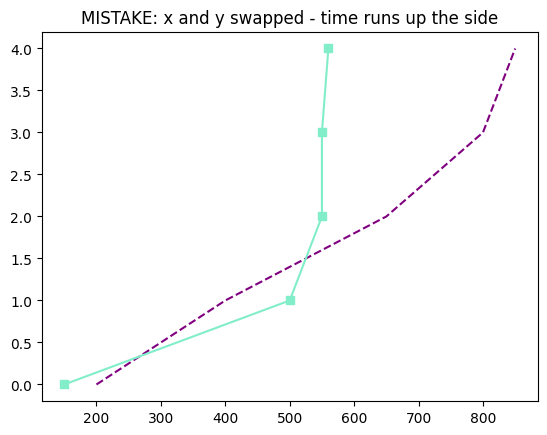

In [5]:
plt.figure()
plt.plot(revenue, time, color='purple', linestyle='--')   # WRONG order
plt.plot(costs, time, color='#82edc9', marker='s')
plt.title('MISTAKE: x and y swapped - time runs up the side')
plt.savefig(CHARTS + '03b_mistake_xy_swapped.png')
plt.show()

**The trap:** "plot A **vs** B" means `plt.plot(B, A)`.
"revenue vs time" -> `plt.plot(time, revenue)`. In words y comes first, in code x comes first.

## 5. Axis and Labels - zooming
**Task:** coffee spending over 12 years; zoom to x 0-12, y 2900-3100.

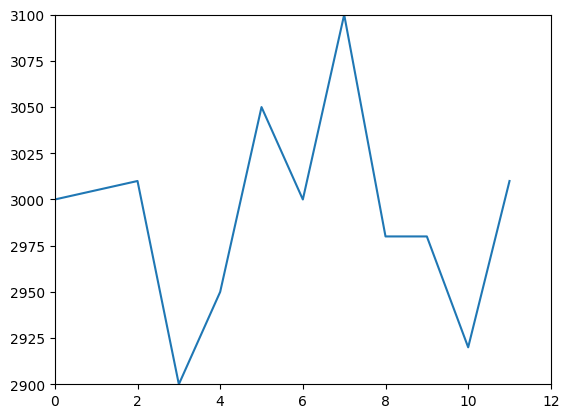

In [6]:
x = range(12)
y = [3000, 3005, 3010, 2900, 2950, 3050, 3000, 3100, 2980, 2980, 2920, 3010]

plt.figure()
plt.plot(x, y)
plt.axis([0, 12, 2900, 3100])
plt.savefig(CHARTS + '04_axis_zoom.png')
plt.show()

```text
plt.axis([xmin, xmax, ymin, ymax])
          \_________/ \_________/
           x-range     y-range        <- always 4 numbers, x first
```
One axis at a time gives the same result: `plt.xlim(0, 12)` and `plt.ylim(2900, 3100)`.

`range(12)` is 0..11 (the end is excluded), so an x-axis up to 12 leaves a little empty space on the right.

**Caution - truncated y-axis:** with y from 2900 to 3100 the line looks wild, but the real variation is only about 7%. Starting the y-axis far above zero exaggerates changes - useful for detail, and a classic way charts mislead. Always check where the y-axis starts.

## 6. Labeling the Axes
**Task:** x-label `'Time'`, y-label `'Dollars spent on coffee'`, title `'My Last Twelve Years of Coffee Drinking'`.

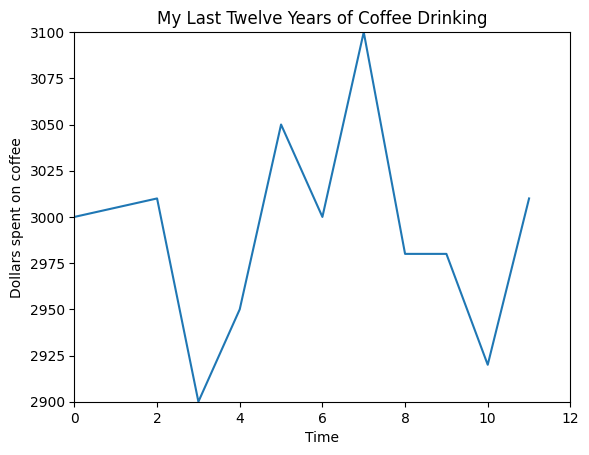

In [7]:
plt.figure()
plt.plot(x, y)
plt.axis([0, 12, 2900, 3100])
plt.xlabel('Time')
plt.ylabel('Dollars spent on coffee')
plt.title('My Last Twelve Years of Coffee Drinking')
plt.savefig(CHARTS + '05_labels.png')
plt.show()

| command | where the text goes |
|---|---|
| `plt.xlabel('...')` | under the x-axis |
| `plt.ylabel('...')` | beside the y-axis |
| `plt.title('...')` | above the chart |

All take a string - `'single'` or `"double"` quotes, but they must match.

**Tip:** put units in labels. `'Time'` -> days? years? -> `'Year'`. Money -> `'Coffee spending (USD)'`.

## 7. Subplots
**Task:** 1 row x 2 columns - `temperature` vs `months` on the left, `flights_to_hawaii` vs `temperature` (scatter) on the right.

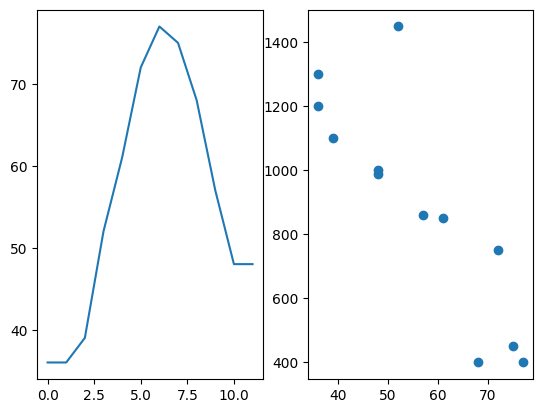

In [8]:
months = range(12)
temperature = [36, 36, 39, 52, 61, 72, 77, 75, 68, 57, 48, 48]
flights_to_hawaii = [1200, 1300, 1100, 1450, 850, 750, 400, 450, 400, 860, 990, 1000]

plt.figure()
plt.subplot(1, 2, 1)                          # LEFT box
plt.plot(months, temperature)

plt.subplot(1, 2, 2)                          # RIGHT box
plt.plot(temperature, flights_to_hawaii, 'o') # 'o' = markers only -> scatter
plt.savefig(CHARTS + '06_subplots.png')
plt.show()

### `plt.subplot(rows, cols, index)` - which box am I drawing in?

![subplot grid guide](charts/guide_subplot_grid.png)

- the **first two numbers** are the size of the grid, the **third** is which box in it
- boxes are numbered in **reading order**: left to right, then the next row - like cells in Excel
- the index goes from 1 to rows x cols, so `subplot(1, 2, 3)` is an error: a 1x2 grid has no box 3

```text
2 rows x 3 columns = 6 boxes:
+-----+-----+-----+
|  1  |  2  |  3  |     subplot(2, 3, 1) -> top left
+-----+-----+-----+     subplot(2, 3, 3) -> top right
|  4  |  5  |  6  |     subplot(2, 3, 4) -> bottom left
+-----+-----+-----+     subplot(2, 3, 6) -> bottom right
```

**Rule:** `subplot()` *selects* a box. Every `plot()`, `title()` or label after it goes into that box - until the next `subplot()` call (the same "everything until the next switch" logic as `show()`).

**Mistakes made:**
- used index 2 for the **left** box - left is 1
- `plt.plot(temperature, months)` - x/y swapped again ("temperature vs months" -> `plot(months, temperature)`)
- forgot the second `plt.subplot()` - both datasets drew into the same box with mismatched scales, which is why it "seemed weird"

**Finance reading (right box):** temperature up, flights down - a **negative** relationship, like the stocks/bonds covariance in `3_pandas/05`. A scatter is the natural chart for "how do two variables relate" - a preview of the Regression track.

## 8. Subplots Part II - mixed layout and spacing
**Task:** one plot on top (full width), two below; then `wspace=0.35` and `bottom=0.2`.

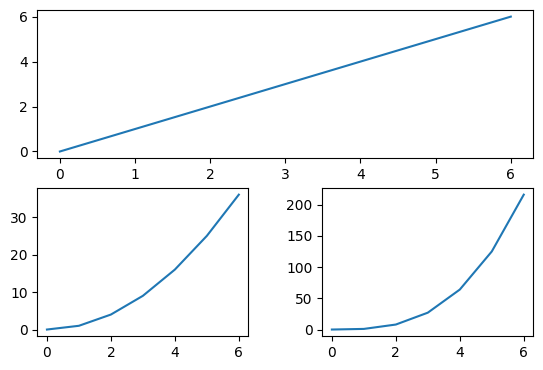

In [9]:
x = range(7)
straight_line = [0, 1, 2, 3, 4, 5, 6]
parabola = [0, 1, 4, 9, 16, 25, 36]
cubic = [0, 1, 8, 27, 64, 125, 216]

plt.figure()
plt.subplot(2, 1, 1)               # top, full width
plt.plot(x, straight_line)

plt.subplot(2, 2, 3)               # bottom left
plt.plot(x, parabola)

plt.subplot(2, 2, 4)               # bottom right
plt.plot(x, cubic)

plt.subplots_adjust(wspace=0.35, bottom=0.2)
plt.savefig(CHARTS + '07_subplots_mixed_layout.png')
plt.show()

### Mixed layouts: every box picks its own grid

![mixed layout guide](charts/guide_subplot_mixed_layout.png)

1. **Draw the figure you want.**
2. **For each box ask:** "in what grid is this box exactly *one* cell?"
   - star: full width, 1 of 2 rows -> 2 rows x 1 col -> `(2, 1, ?)`
   - square / triangle: half width, 1 of 2 rows -> 2 rows x 2 cols -> `(2, 2, ?)`
3. **In that grid, count in reading order** to get the index: star = `(2, 1, 1)`, square = `(2, 2, 3)`, triangle = `(2, 2, 4)`.

**Check:** the rows stay the same everywhere (2) so the boxes line up; the columns change with the box width.

**Alternative (newer, no index counting)** - the layout is drawn as a list:
```python
fig, ax = plt.subplot_mosaic([['star',   'star'],
                              ['square', 'triangle']])
ax['star'].plot(x, straight_line)
ax['square'].plot(x, parabola)
ax['triangle'].plot(x, cubic)
```

### `plt.subplots_adjust(...)` - margins and gaps

![subplots_adjust guide](charts/guide_subplots_adjust.png)

| keyword | meaning | default |
|---|---|---|
| `wspace` | gap between boxes **side by side** | 0.2 |
| `hspace` | gap between **rows** | 0.2 |
| `left` | space before the boxes start | 0.125 |
| `right` | where the boxes **end** (measured from the left) | 0.9 |
| `bottom` | space under the boxes | 0.1 |
| `top` | where the boxes **end** (measured from the bottom) | 0.9 |

Values are fractions of the figure (0 = one edge, 1 = the other). "Horizontal spacing" in the task means `wspace` - the gap between boxes side by side.

## 9. Legends
**Task:** temperatures in Hyrule, Kakariko and Gerudo Valley over a year; add a legend at the lower center.

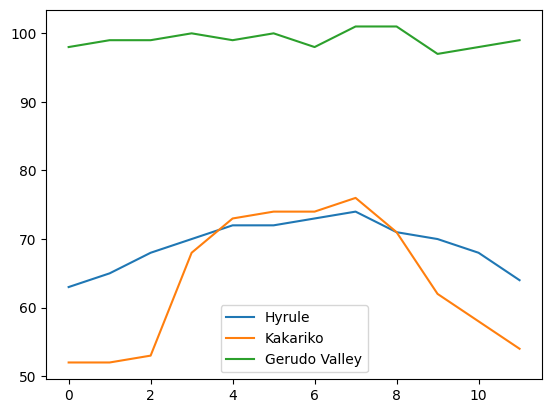

In [10]:
months = range(12)
hyrule = [63, 65, 68, 70, 72, 72, 73, 74, 71, 70, 68, 64]
kakariko = [52, 52, 53, 68, 73, 74, 74, 76, 71, 62, 58, 54]
gerudo = [98, 99, 99, 100, 99, 100, 98, 101, 101, 97, 98, 99]

plt.figure()
plt.plot(months, hyrule)
plt.plot(months, kakariko)
plt.plot(months, gerudo)

legend_labels = ['Hyrule', 'Kakariko', 'Gerudo Valley']
plt.legend(legend_labels, loc=8)
plt.savefig(CHARTS + '08_legend.png')
plt.show()

**Two ways to label lines:**

| A) list in `legend()` | B) `label=` in each `plot()` |
|---|---|
| `plt.plot(x, a)`<br>`plt.plot(x, b)`<br>`plt.legend(['Hyrule', 'Kakariko'])` | `plt.plot(x, a, label='Hyrule')`<br>`plt.plot(x, b, label='Kakariko')`<br>`plt.legend()` - still needed! |
| labels matched to lines **by order** - easy to mix up if lines change | label sits next to its line - safer, the usual style |

**`loc=`** (default 0 = `'best'`) - strings read better: `loc='lower center'` is the same as `loc=8`.
```text
+-----------------+-----------------+-----------------+
| 2 upper left    | 9 upper center  | 1 upper right   |
| 6 center left   | 10 center       | 7 center right  |
| 3 lower left    | 8 lower center  | 4 lower right   |
+-----------------+-----------------+-----------------+
5 = right  (same spot as 7)
```

### Mistake made: a list inside a list
I first wrote `plt.legend([legend_labels], loc=8)`:

['Hyrule', 'Kakariko', 'Gerudo Valley']
[['Hyrule', 'Kakariko', 'Gerudo Valley']]


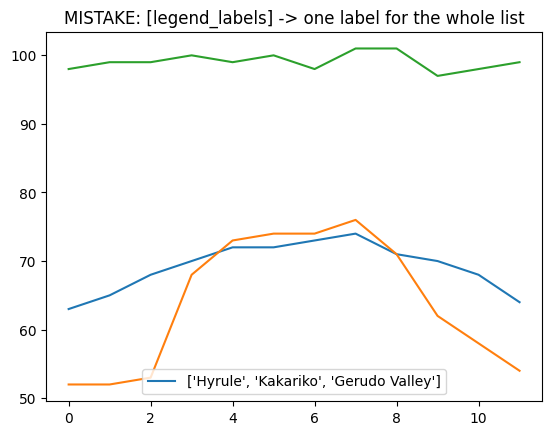

In [11]:
print(legend_labels)      # 3 labels
print([legend_labels])    # 1 label - a whole list

plt.figure()
plt.plot(months, hyrule)
plt.plot(months, kakariko)
plt.plot(months, gerudo)
plt.legend([legend_labels], loc=8)   # WRONG - extra brackets
plt.title('MISTAKE: [legend_labels] -> one label for the whole list')
plt.savefig(CHARTS + '08b_mistake_legend_double_list.png')
plt.show()

`legend_labels` is already a list, so `[legend_labels]` wraps it in a second one. Matplotlib sees **one** label (the whole list as text) for the first line, and nothing for the other two.

## 10. Modify Ticks
**Task:** Dinnersaur subscription conversion by month - x-ticks with month names, y-ticks at 10/25/50/75 shown as percentages.

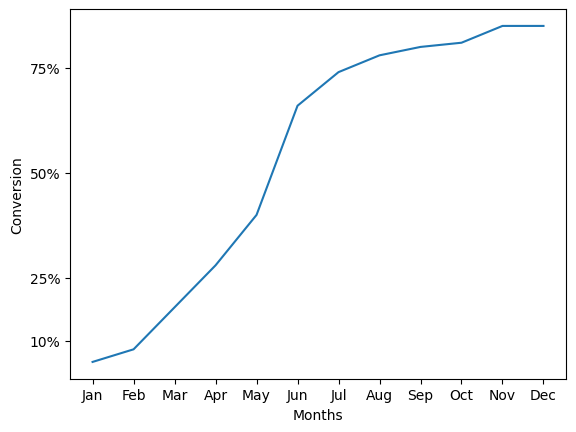

In [12]:
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
months = range(12)
conversion = [0.05, 0.08, 0.18, 0.28, 0.4, 0.66, 0.74, 0.78, 0.8, 0.81, 0.85, 0.85]

plt.figure()
plt.xlabel('Months')
plt.ylabel('Conversion')
plt.plot(months, conversion)

ax = plt.subplot()
ax.set_xticks(months)
ax.set_xticklabels(month_names)
ax.set_yticks([0.10, 0.25, 0.5, 0.75])
ax.set_yticklabels(['10%', '25%', '50%', '75%'])
plt.savefig(CHARTS + '09_ticks.png')
plt.show()

### New style: `ax.` instead of `plt.`
`ax` is **one specific chart** (an axes object). With several subplots, `plt.` doesn't say *which* chart you mean - `ax` does. `ax = plt.subplot()` is the same as `plt.subplot(1, 1, 1)`: the one chart.

| method | sets |
|---|---|
| `ax.set_xticks([...])` | **where** the ticks sit (numbers) |
| `ax.set_xticklabels([...])` | **what** they say (any text) |
| `ax.set_yticks` / `ax.set_yticklabels` | the same for the y-axis |

```text
ticks:   0      1      2     ...  11
labels: 'Jan'  'Feb'  'Mar'  ... 'Dec'     <- matched by position
```

Here `ax` comes *after* `plt.plot()` - that works, because `plt.subplot()` with no arguments returns the chart that already exists. The clearer habit: get `ax` first, then draw on it, then adjust it.

### Faster way to show percentages (more advanced)
Typing `'10%'`, `'25%'` ... by hand breaks as soon as the ticks change. Two better options:

**(a) Build the labels from the numbers** - f-string + list comprehension:
```python
y_ticks = [0.10, 0.25, 0.5, 0.75]
ax.set_yticks(y_ticks)
ax.set_yticklabels([f'{v:.0%}' for v in y_ticks])
```
- `f'{v:.0%}'` multiplies by 100, adds %, 0 decimals: `0.25 -> '25%'` (`:.1%` gives `'25.0%'`)
- `[... for v in y_ticks]` is a **list comprehension**: do the same thing to every item and build a new list. R: `paste0(y_ticks * 100, "%")`

**(b) Let Matplotlib format the whole axis** - `PercentFormatter`. It comes **with** Matplotlib (`matplotlib.ticker`), so there's nothing extra to install - just one more import. `1.0` means "the value 1.0 is 100%". It works on every tick, also ones you didn't choose, so no `set_yticklabels` is needed - the standard for return and volatility charts (`PercentFormatter(1.0, decimals=1)` shows 0.0236 as 2.4%).

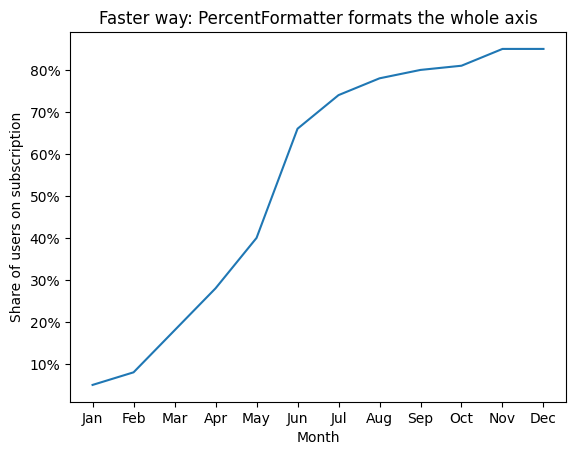

In [13]:
from matplotlib.ticker import PercentFormatter

plt.figure()
ax = plt.subplot()                          # 1. get the axes first
ax.plot(months, conversion)                 # 2. draw on it
ax.set_xticks(months, labels=month_names)   # 3. newer: ticks + labels in one call
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel('Month')
ax.set_ylabel('Share of users on subscription')
ax.set_title('Faster way: PercentFormatter formats the whole axis')
plt.savefig(CHARTS + '09b_ticks_percentformatter.png')
plt.show()

| approach | code | when |
|---|---|---|
| hand-typed labels | `['10%', ...]` | fine for 3 ticks, breaks if the ticks change |
| f-string labels | `f'{v:.0%}'` | labels always match your chosen ticks |
| `PercentFormatter` | `set_major_formatter(...)` | whole axis, any ticks |